# <a id='toc1_'></a>[Preprocesado](#toc0_)

**Table of contents**<a id='toc0_'></a>    
- [Preprocesado](#toc1_)    
  - [Carga del dataset](#toc1_1_)    
  - [División train / val / test](#toc1_2_)    
  - [Pesos de clase](#toc1_3_)    
  - [Transformaciones y aumento de datos](#toc1_4_)    
  - [Dataset y DataLoader](#toc1_5_)    
  - [Exportación](#toc1_6_)    
  - [Resumen](#toc1_7_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

> En este notebook preparamos los datos para entrenar el modelo: dividimos en train/val/test sin fugas, calculamos los pesos de clase y definimos las transformaciones de las imágenes. Partimos del dataset etiquetado en `02_feature_engineering` (`styles_labeled.csv`).

**Objetivos:**
1. Dividir en train/val/test manteniendo la proporción de clases y sin imágenes duplicadas entre conjuntos.
2. Calcular los pesos de clase con el conjunto de entrenamiento.
3. Definir las transformaciones y el aumento de datos.
4. Comprobar que el `Dataset` y el `DataLoader` de PyTorch funcionan.
5. Exportar el dataset con el split (`styles_splits.csv`) y los pesos de clase (`class_weights.json`).

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torch.utils.data import DataLoader
from sklearn.utils.class_weight import compute_class_weight

# Estilo de gráficos
plt.style.use('seaborn-v0_8-whitegrid')

from fashion_mlops.config import PROCESSED_DATA_DIR, IMAGES_DIR, RANDOM_STATE, IMAGENET_MEAN, IMAGENET_STD
from fashion_mlops.data.make_dataset import make_grouped_splits
from fashion_mlops.data.dataset import FashionDataset, get_transforms

## <a id='toc1_1_'></a>[Carga del dataset](#toc0_)

In [2]:
df = pd.read_csv(PROCESSED_DATA_DIR / "styles_labeled.csv")

with open(PROCESSED_DATA_DIR / "label_mappings.json") as f:
    label_mappings = json.load(f)

classes = list(label_mappings["masterCategory"])

print(f"Dataset cargado: {df.shape[0]} filas, {df.shape[1]} columnas.")
print(f"Clases: {label_mappings['masterCategory']}")

Dataset cargado: 44414 filas, 14 columnas.
Clases: {'Accessories': 0, 'Apparel': 1, 'Footwear': 2, 'Other': 3, 'Personal Care': 4}


## <a id='toc1_2_'></a>[División train / val / test](#toc0_)

Dividimos en 70/15/15 aproximadamente. Hacemos un split **estratificado**, para que cada conjunto tenga la misma proporción de clases (importante con `Other`, que tiene muy pocos ejemplos), y **agrupado por `file_hash`**, para que una imagen duplicada no acabe a la vez en train y en test.

In [3]:
df["split"] = make_grouped_splits(df, target_col="masterCategory_grouped", random_state=RANDOM_STATE)

df["split"].value_counts()

split
train    31723
val       6346
test      6345
Name: count, dtype: int64

Comprobamos que la proporción de clases (%) es la misma en los tres conjuntos:

In [4]:
(pd.crosstab(df["masterCategory_grouped"], df["split"], normalize="columns") * 100).round(2)

split,test,train,val
masterCategory_grouped,,,
Accessories,25.37,25.38,25.39
Apparel,48.16,48.17,48.16
Footwear,20.76,20.76,20.75
Other,0.30,0.29,0.30
Personal Care,5.41,5.41,5.40


Las proporciones son prácticamente idénticas. Comprobamos también que ningún grupo de imágenes duplicadas está repartido entre varios conjuntos:

In [5]:
n_leaks = (df.groupby("file_hash")["split"].nunique() > 1).sum()

print(f"Grupos de imágenes repartidos en más de un conjunto: {n_leaks}")

Grupos de imágenes repartidos en más de un conjunto: 0


## <a id='toc1_3_'></a>[Pesos de clase](#toc0_)

Como las clases están desbalanceadas, calculamos un peso para cada una que usaremos en la función de pérdida, para que el modelo no ignore las clases pequeñas. Los calculamos **solo con train**, para no usar información de val/test:

In [6]:
train_labels = df.loc[df["split"] == "train", "masterCategory_idx"]

weights = compute_class_weight(class_weight="balanced", classes=np.arange(len(classes)), y=train_labels)
class_weights = {label: round(float(weight), 4) for label, weight in zip(classes, weights)}

class_weights

{'Accessories': 0.7881,
 'Apparel': 0.4152,
 'Footwear': 0.9635,
 'Other': 69.7209,
 'Personal Care': 3.6952}

`Other` tiene un peso de ~70 frente a ~0,4 de `Apparel`. Es un peso muy alto que puede hacer el entrenamiento inestable, así que en el modelado probaremos con y sin pesos.

## <a id='toc1_4_'></a>[Transformaciones y aumento de datos](#toc0_)

Las transformaciones están en `fashion_mlops.data.dataset.get_transforms`:
- Todas las imágenes: pasar a RGB (hay 431 en escala de grises), redimensionar a 224x168 manteniendo la proporción y normalizar con la media y desviación de ImageNet (porque usaremos un modelo preentrenado).
- Solo en train: volteo horizontal, pequeñas rotaciones y desplazamientos y cambios de brillo y contraste.

Veamos cómo quedan algunas imágenes aumentadas, una de cada clase:

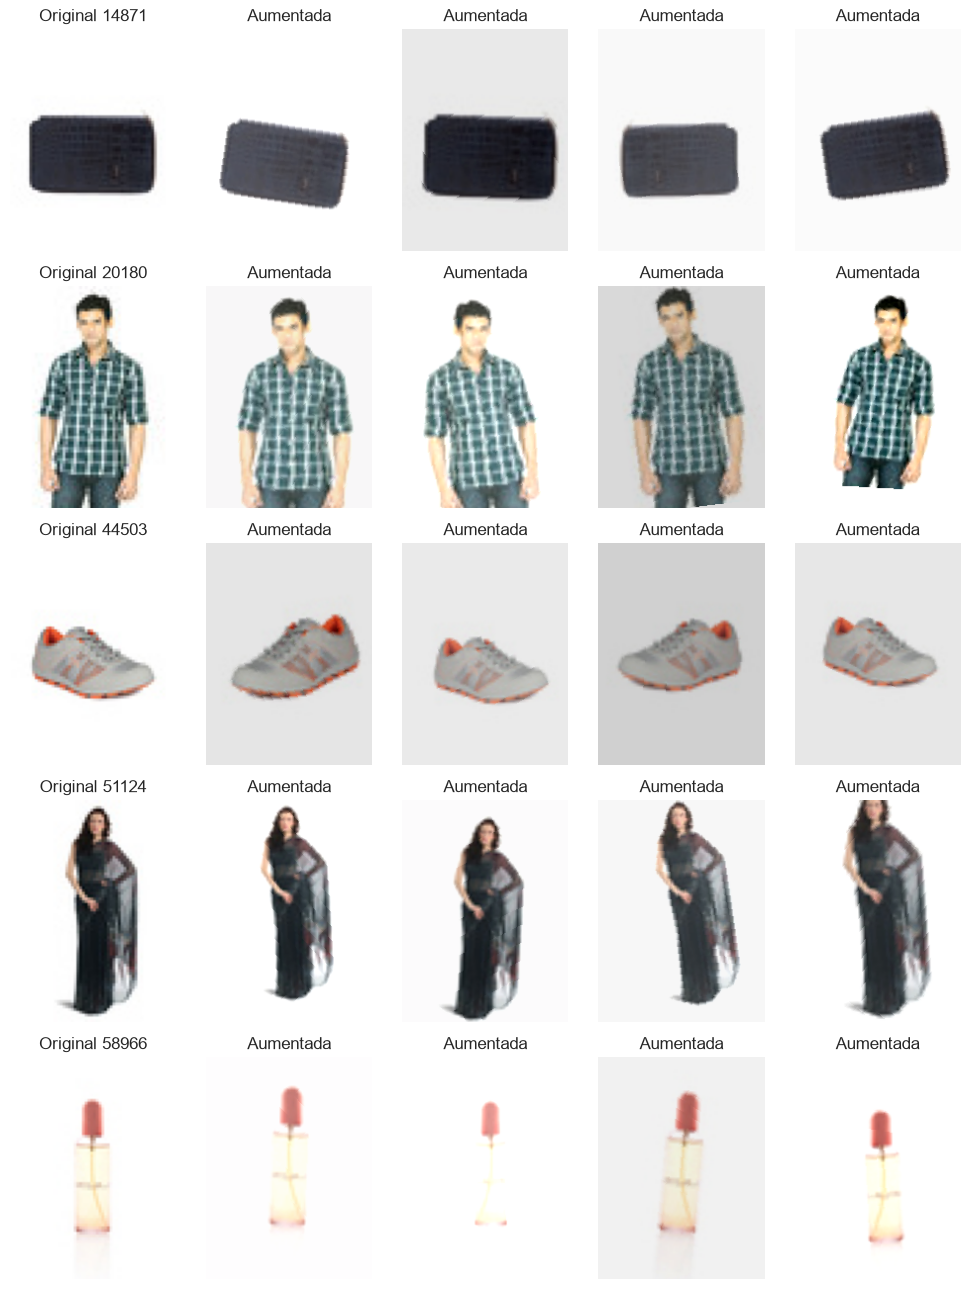

In [7]:
# Para mostrar las imágenes deshacemos la normalización
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

sample_ids = df.groupby("masterCategory_grouped").sample(1, random_state=RANDOM_STATE)["id"].to_list()
train_transform = get_transforms(train=True)
torch.manual_seed(RANDOM_STATE)

fig, axes = plt.subplots(len(sample_ids), 5, figsize=(10, 2.6 * len(sample_ids)))

for row, image_id in zip(axes, sample_ids):
    image = Image.open(IMAGES_DIR / f"{image_id}.jpg").convert("RGB")
    row[0].imshow(image)
    row[0].set_title(f"Original {image_id}")

    for ax in row[1:]:
        augmented = (train_transform(image) * std + mean).clamp(0, 1)
        ax.imshow(augmented.permute(1, 2, 0))
        ax.set_title("Aumentada")

    for ax in row:
        ax.axis("off")

plt.tight_layout()
plt.show()

Las variaciones son pequeñas y el producto se sigue reconociendo, que es lo que buscamos.

## <a id='toc1_5_'></a>[Dataset y DataLoader](#toc0_)

Creamos un `Dataset` por conjunto (solo train lleva aumento de datos) y comprobamos que los `DataLoader` devuelven batches con la forma correcta:

In [8]:
datasets = {
    split: FashionDataset(
        df[df["split"] == split],
        IMAGES_DIR,
        label_col="masterCategory_idx",
        transform=get_transforms(train=(split == "train"))
    )
    for split in ["train", "val", "test"]
}

loaders = {
    split: DataLoader(dataset, batch_size=64, shuffle=(split == "train"))
    for split, dataset in datasets.items()
}

for split, loader in loaders.items():
    images, labels = next(iter(loader))
    print(f"{split}: {len(datasets[split])} imágenes, {len(loader)} batches | batch: {tuple(images.shape)}, etiquetas: {labels.dtype}")

train: 31723 imágenes, 496 batches | batch: (64, 3, 224, 168), etiquetas: torch.int64
val: 6346 imágenes, 100 batches | batch: (64, 3, 224, 168), etiquetas: torch.int64
test: 6345 imágenes, 100 batches | batch: (64, 3, 224, 168), etiquetas: torch.int64


## <a id='toc1_6_'></a>[Exportación](#toc0_)

Guardamos el dataset con la columna `split` y los pesos de clase para usarlos en `04_modeling`:

In [9]:
df.to_csv(PROCESSED_DATA_DIR / "styles_splits.csv", index=False)

with open(PROCESSED_DATA_DIR / "class_weights.json", "w") as f:
    json.dump({"masterCategory": class_weights}, f, indent=2)

print(f"Dataset exportado: {df.shape[0]} filas, {df.shape[1]} columnas.")

Dataset exportado: 44414 filas, 15 columnas.


## <a id='toc1_7_'></a>[Resumen](#toc0_)

- Split estratificado y agrupado por hash: 31.723 / 6.346 / 6.345 imágenes (≈71/14/14), misma proporción de clases y sin duplicados entre conjuntos.
- Pesos de clase calculados con train. El de `Other` es muy alto (~70), lo tendremos en cuenta al entrenar.
- Imágenes en RGB, 224x168, normalizadas con ImageNet y con aumento de datos solo en train.
- El `Dataset` y los `DataLoader` funcionan.

En `04_modeling` entrenaremos el modelo baseline con transfer learning.